# 第III部：Euler方程式の近似リーマンソルバー

**比較対象：Roe、LLF (Rusanov)、HLL、HLLC**

区分一定再構築と前進Eulerを共通にし、数値流束が区別する波の違いを調べます。

[I 移流・Burgers](01_advection_burgers.ipynb) · [II Eulerの古典的解法](02_euler_classical.ipynb) · [III 近似リーマンソルバー](03_euler_riemann_solvers.ipynb) · [IV 空間再構築](04_spatial_reconstruction.ipynb) · [V 時間積分](05_time_integration.ipynb)

数値流束・空間再構築・時間積分は区別して比較します。LWは滑らかな解で2次精度です。
第III部で数値流束、第IV部で空間再構築、第V部で時間積分をそれぞれ比較します。
表示名は `LLF (Rusanov)`、内部識別子は `LLF` です。

## 実行方法と設定

リポジトリ一式を取得し、`notebooks/` と `src/` の配置を保ってください。
計算は `src/euler1d_core.py`、比較・描画は `src/euler1d_study.py` を使用します。
設定セルを確認し、カーネルを再起動して上から実行してください。
`run_convergence` は収束試験、`run_extras` は追加実験、`run_shu_osher` はShu–Osher問題、`run_movies` は動画です。
動画は標準で有効です。追加実験・Shu–Osherは初期設定で無効です。

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/euler1d_study.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("リポジトリ一式を取得し、notebooks/ と src/ の配置を保って実行してください。")
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
from euler1d_core import PROBLEMS, run_unit_tests
from euler1d_study import PARTS, RUN_CACHE, get_run, run_part, summarize, show_table, plot_profiles, plot_pressure_minimum, run_convergence, shu_reference, export_results, make_part_animation

### 時間発展動画の問題を選択する

設定セルの `CFG["movie_problem"]` に、次のいずれかの文字列を指定します。

| 設定する値 | 問題 | 主な観察点 |
|:--|:--|:--|
| `entropy` | 滑らかなエントロピー波の移流 | 波形の拡散・位相誤差 |
| `contact` | 移動する接触不連続面 | 接触面の数値拡散・振動 |
| `contact_static` | 静止する接触不連続面 | 静止した密度不連続の保持 |
| `sod` | Sod衝撃波管 | 衝撃波・接触不連続面・希薄波 |
| `double_rarefaction` | 二重希薄波 | 低密度・低圧力での頑健性、計算停止 |
| `lax` | Lax衝撃波管 | Sodとは異なる衝撃波条件 |
| `transonic` | 音速をまたぐ希薄波 | エントロピー補正の影響 |

`shu_osher` は数値参照解を必要とするため、この簡易動画機能の選択肢には含めません。Shu–Osherの計算・静止図は `run_shu_osher` で実行できます。

動画を無効にする場合は `CFG["run_movies"] = False` に設定してください。

In [2]:
PART = "modern"
CFG = {
    "gamma": 1.4,
    "cfl": 0.4,
    "n_basic": 200,
    "n_convergence": (100, 200, 400, 800),
    "limiter": "minmod",
    "wave_speeds": "einfeldt",
    "roe_entropy": 0.1,
    "n_shu_osher": 400,
    "n_reference": (1600, 3200),
    "reference_limiter": "mc",
    "run_convergence": True,
    "run_shu_osher": False,
    "run_extras": False,
    "run_movies": True,
    "movie_problem": "sod",  # 選択肢は直前の表を参照
    "movie_frames": 61,
    "export_results": True,
}
RUN_CACHE.clear()
RESULTS = {}
reference_fine = None
print("Python:", sys.version.split()[0], "NumPy:", np.__version__)
print(CFG)
OUTPUT_DIR = ROOT / "four_part_outputs" / PART
print("Part:", PARTS[PART]["title"])
print("Output directory:", OUTPUT_DIR)

Python: 3.11.18 NumPy: 2.4.6
{'gamma': 1.4, 'cfl': 0.4, 'n_basic': 200, 'n_convergence': (100, 200, 400, 800), 'limiter': 'minmod', 'wave_speeds': 'einfeldt', 'roe_entropy': 0.1, 'n_shu_osher': 400, 'n_reference': (1600, 3200), 'reference_limiter': 'mc', 'run_convergence': True, 'run_shu_osher': False, 'run_extras': False, 'run_movies': True, 'movie_problem': 'sod', 'movie_frames': 61, 'export_results': True}
Part: Part III: practical fluxes, first-order baseline
Output directory: /home/runner/work/euler1d-scheme-comparison/euler1d-scheme-comparison/four_part_outputs/modern


### 共通の方程式と保存形

無粘性・断熱の理想気体を扱います。量はすべて無次元です。$E$は**単位体積当たりの全エネルギー**、$e$は**単位質量当たりの内部エネルギー**です。

$$
\frac{\partial\boldsymbol U}{\partial t}+\frac{\partial\boldsymbol F}{\partial x}=0,
\qquad
\boldsymbol U=\begin{pmatrix}\rho\\\rho u\\E\end{pmatrix},
\qquad
\boldsymbol F=\begin{pmatrix}\rho u\\\rho u^2+p\\u(E+p)\end{pmatrix}.
$$
$$
E=\frac{p}{\gamma-1}+\frac12\rho u^2,\qquad
c=\sqrt{\frac{\gamma p}{\rho}},\qquad e=\frac{p}{(\gamma-1)\rho}.
$$

特性速度は$u-c,\ u,\ u+c$です。中央の波が接触・エントロピー波を担います。[R1]

コードでは`U.shape == (N, 3)`とし、`U[:, 0]`が密度、`U[:, 1]`が運動量密度、`U[:, 2]`が全エネルギー密度です。
基本変数`W`は$(\rho,u,p)$の順です。境界流束を差し引く更新式を全方式で共有します。

$$
\overline{\boldsymbol U}^{\,n+1}_i=\overline{\boldsymbol U}^{\,n}_i-
\frac{\Delta t}{\Delta x}(\boldsymbol F^*_{i+1/2}-\boldsymbol F^*_{i-1/2}).
$$

ここで格子上の未知量は**点値ではなくセル平均**です。
一様格子上で区分一定の状態を用いる場合、以下のLF/LWの保存形実装は対応する古典的な差分更新になります。

### 共通のテスト問題と初期条件

すべて$\gamma=1.4$の設定です。$W=(\rho,u,p)$と表記します。
矩形波のセル内占有率と正弦波のセル平均を解析的に求め、格子点で初期条件を単純にサンプルする誤差を避けます。

| キー | 領域・時刻 | 初期条件の要点 | 境界 |
|:--|:--|:--|:--|
| `entropy` | $[0,1],\ t=1$ | $\rho=1+0.2\sin(2\pi x),\ u=p=1$ | 周期 |
| `contact` | $[0,1],\ t=0.25$ | $0.25\le x<0.45$で$\rho=2$、他は1。$u=p=1$ | 周期 |
| `contact_static` | $[0,1],\ t=0.25$ | 同じ矩形密度、$u=0,\ p=1$ | 周期 |
| `sod` | $[0,1],\ x_0=0.5,\ t=0.2$ | $W_L=(1,0,1),\ W_R=(0.125,0,0.1)$ | 流出 |
| `double_rarefaction` | $[-0.5,0.5],\ x_0=0,\ t=0.15$ | $W_L=(1,-2,0.4),\ W_R=(1,2,0.4)$ | 流出 |
| `shu_osher` | $[-5,5],\ x_0=-4,\ t=1.8$ | 左は衝撃波通過後、右は$\rho=1+0.2\sin(5x),\ u=0,\ p=1$ | 左固定流入・右流出 |
| `transonic` | $[0,1],\ x_0=0.3,\ t=0.2$ | $W_L=(1,0.75,1),\ W_R=(0.125,0,0.1)$ | 流出 |
| `lax` | $[-0.5,0.5],\ x_0=0,\ t=0.14$ | $W_L=(0.445,0.698,3.528),\ W_R=(0.5,0,0.571)$ | 流出 |

SodとShu–Osherの設定は文献・公式テスト例と対応します。[R4, R5]
Shu–Osherの左状態は$\rho_L=27/7,\ u_L=20\sqrt{1.4}/9,\ p_L=31/3$とし、よく用いられる小数値の丸めを避けています。
$\gamma$を変更した場合、この左状態が同じMach数の衝撃波に対応するとは限りません。

流出境界は端のセルをゴーストセルにコピーする簡単な条件で、完全な無反射境界ではありません。
指定した終了時刻では、Sodなどのリーマン問題の主要波面は境界に達しません。

Shu–Osher・Lax・音速をまたぐ希薄波は追加実験で扱います。Laxはここでは**問題の名称**で、LF/LWだけを使うという意味ではありません。

### 厳密解と比較の基準

エントロピー波と接触不連続面は、そのまま速度$u$で平行移動します。
Sod・二重希薄波・追加のリーマン問題は、星領域の圧力$p_*$を

$$
f_L(p_*)+f_R(p_*)+u_R-u_L=0
$$

から二分法で求めます。希薄波と衝撃波で分岐する$f_K$、自己相似変数$\xi=(x-x_0)/t$における解をコードに明示しています。[R1]
ここでの「厳密解」は厳密なリーマン解の構造に基づく数値評価で、非線形方程式の解法と数値積分の許容誤差は残ります。

**誤差は保存変数をセル平均した厳密解と比較します。** 波面の位置で積分区間を分割してからGauss積分するので、不連続を横切る単純な台形積分は使いません。
速度と圧力の比較基準は$W(\overline U_{\rm exact})$です。これは一般に$\overline{W(U_{\rm exact})}$とは異なります。

図には見やすさのため点値の厳密解を実線で示しますが、誤差表にはセル平均基準を使います。
Shu–Osherは厳密解を用いず、後で別に高解像度の**数値参照解**を計算します。

この実装は**物理的な真空を含むリーマン解には対応していません**。
真空条件$u_R-u_L\ge2(c_L+c_R)/(\gamma-1)$を検出すると明示的に停止します。
ここで使う二重希薄波問題は真空条件を満たさず、中央の密度・圧力は正です。

### 時間刻み・破綻・保存則

時間刻みは各計算で

$$
\Delta t=C_{\rm CFL}\frac{\Delta x}{\max_i(|u_i|+c_i)}
$$

から求めます。**共通なのはCFL数と選択規則であり、時々刻々の$\Delta t$が全方式で同じとは限りません。**
終端で極端に短い最後のステップだけを取ると、LFでは$\Delta x/\Delta t$が急増します。
これを避けるため、残り時間がCFL上限の2ステップ以内になったら残りを1または2等分します。この規則は全方式に共通です。

非周期境界では領域内の総量が変化しても保存則違反とは限りません。$Q=\sum_iU_i\Delta x$として

$$
R_Q=Q(t)-Q(0)-\int_0^t(F_{\rm left}^*-F_{\rm right}^*)\,dt'
$$

を測定します。SSP-RK2の境界流束も段階の重み$1/2,1/2$で積算します。
表の`balance_max`は質量・運動量・全エネルギーの$|R_Q|$の最大値で、無次元の絶対残差です。
保存残差が小さいことだけで解の精度がよいとは判断できません。

`failed`の場合、`t_reached`は**最後に受理した時刻**です。
`failure_trial_end`は失敗した試行ステップの終端時刻で、中間段階での失敗なら実際の検出段階は`failure_reason`に表示されます。
失敗した計算の最終時刻誤差は計算しません。

### 評価指標

密度の誤差は、領域長$L$で規格化した平均$L_1$誤差

$$
\epsilon_1(\rho)=\frac1L\sum_i\Delta x\,|\overline\rho_i-\overline\rho_{i,{\rm exact}}|
$$

です。滑らかな周期波については、基本Fourierモードの振幅比`amp_ratio`と位相誤差`phase_rad`も測定します。
接触面の`rho_overshoot`は$\max(\rho)-2$の正の部分、`rho_undershoot`は$1-\min(\rho)$の正の部分です。
`mixed_length`は$1.1<\rho<1.9$のセル幅の合計で、二つの遷移領域と振動の影響を含む補助指標です。単一の接触面の厳密な10–90%幅ではありません。

図は岡部・伊藤パレット、英語ラベル、線種とマーカーの併用に統一します。
RoeとHLLCがほぼ重なること自体も、このテストでは重要な結果です。

### 計算本体の自己検証
9グループの基本検証を実行します。これは基本的な回帰テストであり、任意の初期条件での正確さ・正値性を保証するものではありません。

In [3]:
checks = run_unit_tests(CFG["gamma"])
for i, name in enumerate(checks, 1):
    print(f"PASS {i}: {name}")
print("Validation groups:", len(checks))

PASS 1: primitive/conserved round trip
PASS 2: F*(U,U) = F(U), all six solvers
PASS 3: symmetric-speed HLL equals LLF
PASS 4: stationary contact: Roe, HLLC, and Richtmyer LW
PASS 5: periodic conservation, all six solvers
PASS 6: MUSCL/SSP-RK2 periodic conservation
PASS 7: Sod star pressure and velocity
PASS 8: exact-solution quadrature and positive reference states
PASS 9: nonperiodic boundary-flux budget
Validation groups: 9


<a id="part-3"></a>
# 第III部：現代の実用的手法 — 数値流束の比較

**問い：同じ1次精度の更新の中で、どの波を区別するかが解にどう現れるか。**

ここではRoe、LLF (Rusanov)、HLL、HLLCだけを比較します。
共通の区分一定再構成と前進Eulerで、数値流束の違いを切り分けます。
この1次精度の構成は比較の基準です。第IV部では同じ流束のまま、時間積分を固定して空間再構築を比較します。

LLF (Rusanov)では
$$
F^*_{\rm LLF}=\frac{F_L+F_R}{2}-\frac{\alpha_{LR}}2(U_R-U_L),\qquad
\alpha_{LR}=\max(|u_L|+c_L,|u_R|+c_R).
$$
古典的LFの$\Delta x/\Delta t$を、局所波速に基づく係数で置き換えた数値流束です。
実装では内部名`LLF`を用い、図では`LLF (Rusanov)`と表示します。

### Roe流束とエントロピー補正

Roe平均を

$$
\widetilde u=\frac{\sqrt{\rho_L}u_L+\sqrt{\rho_R}u_R}{\sqrt{\rho_L}+\sqrt{\rho_R}},\qquad
\widetilde H=\frac{\sqrt{\rho_L}H_L+\sqrt{\rho_R}H_R}{\sqrt{\rho_L}+\sqrt{\rho_R}},\qquad
\widetilde c^2=(\gamma-1)\left(\widetilde H-\frac12\widetilde u^2\right)
$$

と定義します。$H=(E+p)/\rho$です。$\Delta\boldsymbol U=\sum_k\beta_k\boldsymbol r_k$と分解すると、

$$
\boldsymbol F^*_{\rm Roe}=\frac12(\boldsymbol F_L+\boldsymbol F_R)
-\frac12\sum_{k=1}^3|\widetilde\lambda_k|\,\beta_k\boldsymbol r_k
$$

となります。具体的な波の強度と固有ベクトルは `src/euler1d_core.py` の `numerical_flux` に明示しています。[R2]

本Notebookでは、音響波$\widetilde u\pm\widetilde c$の絶対値に、次のHarten型の簡易正則化を選びます。

$$
|\lambda|_\delta=
\begin{cases}
|\lambda|,&|\lambda|\ge\delta,\\
(\lambda^2+\delta^2)/(2\delta),&|\lambda|<\delta,
\end{cases}
\qquad \delta=\varepsilon_{\rm ent}\widetilde c.
$$

標準値は$\varepsilon_{\rm ent}=0.1$です。`roe_entropy=0.0`なら補正しません。
**接触波$\widetilde u$にはこの補正を加えません。**
この簡易補正は低密度・低圧力の正値性対策ではなく、あらゆる希薄波での保証を与えるものでもありません。[R7]

### HLLとHLLC：外側波速を共通にして比較する

HLLは最も左向きと右向きの波速$S_L,S_R$で挟まれた領域を一つの状態で近似します。

$$
\boldsymbol F^*_{\rm HLL}=
\begin{cases}
\boldsymbol F_L,&0\le S_L,\\
\dfrac{S_R\boldsymbol F_L-S_L\boldsymbol F_R+S_LS_R(\boldsymbol U_R-\boldsymbol U_L)}{S_R-S_L},&S_L<0<S_R,\\
\boldsymbol F_R,&S_R\le0.
\end{cases}
$$

標準設定はEinfeldtの波速推定

$$
S_L=\min(u_L-c_L,\widetilde u-\widetilde c),\qquad
S_R=\max(u_R+c_R,\widetilde u+\widetilde c)
$$

です。したがって図では**HLL (HLLE)**と表示します。[R2]
`wave_speeds="davis"`では両側の$u\pm c$の最小・最大を用います。
`"symmetric"`では$S_L=-\alpha_{LR},S_R=\alpha_{LR}$として、HLLがLLFと一致することを確認できます。

HLLCはHLLの中央領域を、接触波$S_*$で二つに分けます。

$$
S_* = \frac{p_R-p_L+\rho_Lu_L(S_L-u_L)-\rho_Ru_R(S_R-u_R)}
{\rho_L(S_L-u_L)-\rho_R(S_R-u_R)}.
$$

$K=L,R$について

$$
\rho_{*K}=\rho_K\frac{S_K-u_K}{S_K-S_*},\qquad
E_{*K}=\rho_{*K}\left[\frac{E_K}{\rho_K}+(S_*-u_K)
\left(S_*+\frac{p_K}{\rho_K(S_K-u_K)}\right)\right]
$$

を使い、$\boldsymbol U_{*K}=(\rho_{*K},\rho_{*K}S_*,E_{*K})$を構成します。
中央領域の流束は$\boldsymbol F_K+S_K(\boldsymbol U_{*K}-\boldsymbol U_K)$です。[R3, R6]

ここではHLLとHLLCに同じ$S_L,S_R$を使います。
この選択で完走したという実験結果を、高次再構成や任意の波速推定を含めた一般的な正値性保証と混同しないでください。

### III.1 滑らかなエントロピー波

4流束を同じ1次精度の条件で比較します。ここでの誤差を、第II部の2次精度LWと同次数の比較だとは解釈しません。

Part III: practical fluxes, first-order baseline | entropy: Roe=ok, LLF (Rusanov)=ok, HLL (HLLE)=ok, HLLC=ok


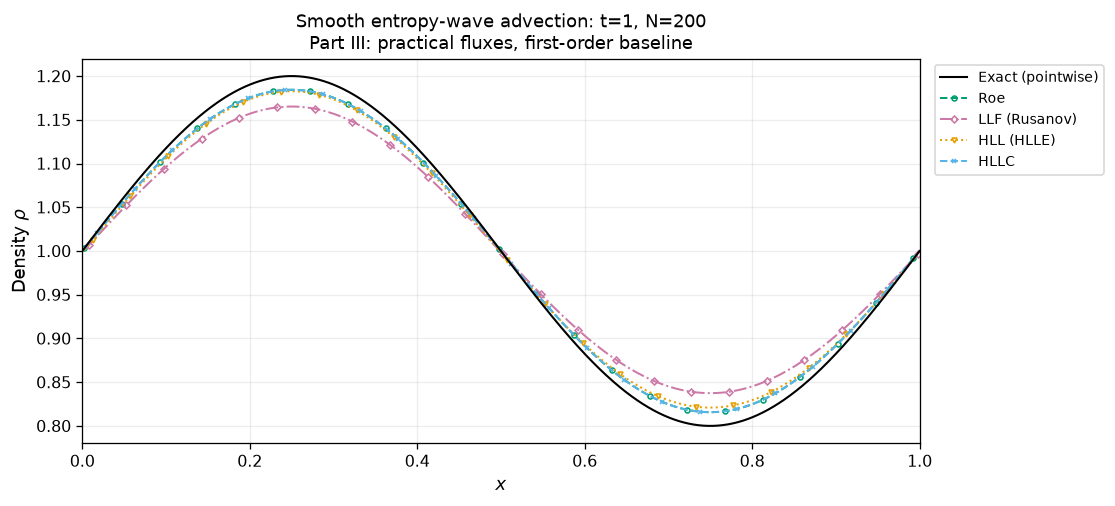

method,n,order,status,t_reached,L1_rho,rho_min,p_min,balance_max
Roe,200,1,ok,1,0.009984,0.8157,1,1.332e-15
LLF (Rusanov),200,1,ok,1,0.02296,0.8375,1,1.776e-15
HLL (HLLE),200,1,ok,1,0.01216,0.821,1,2.22e-15
HLLC,200,1,ok,1,0.009984,0.8157,1,1.332e-15


[{'problem': 'entropy',
  'solver': 'Roe',
  'order': 1,
  'n': 200,
  'cfl': 0.4,
  'limiter': 'constant',
  'wave_speeds': 'einfeldt',
  'roe_entropy': 0.1,
  'status': 'ok',
  't_reached': 1.0,
  't_target': 1.0,
  'steps': 1159,
  'seconds': 0.22532509299999504,
  'rho_min': 0.8157114734773657,
  'p_min': 0.999999999999998,
  'balance_max': 1.3322676295501878e-15,
  'mass_balance': np.float64(6.661338147750939e-16),
  'momentum_balance': np.float64(4.440892098500626e-16),
  'energy_balance': np.float64(-1.3322676295501878e-15),
  'L1_rho': np.float64(0.00998396597451838),
  'L1_u': np.float64(6.06736882957648e-16),
  'L1_p': np.float64(6.06736882957648e-16),
  'amp_ratio': 0.9215862590831362,
  'phase_rad': 0.0005599544796720028,
  'rho_overshoot': nan,
  'rho_undershoot': nan,
  'mixed_length': nan,
  'failure_trial_end': nan,
  'failure_dt': nan,
  'failure_rho_min': nan,
  'failure_p_min': nan,
  'failure_reason': '',
  'method': 'Roe'},
 {'problem': 'entropy',
  'solver': 'LLF'

In [4]:
RESULTS[("modern", "entropy")] = run_part("modern", "entropy", CFG)
runs = RESULTS[("modern", "entropy")]
plot_profiles(runs, fields=('rho',), logarithmic=False, title_suffix=PARTS["modern"]["title"])
summarize(runs)

### III.2 静止する接触面

Roe/HLLCとLLF (Rusanov)/HLLの違いを確認します。保存量の収支も表で検査してください。

Part III: practical fluxes, first-order baseline | contact_static: Roe=ok, LLF (Rusanov)=ok, HLL (HLLE)=ok, HLLC=ok


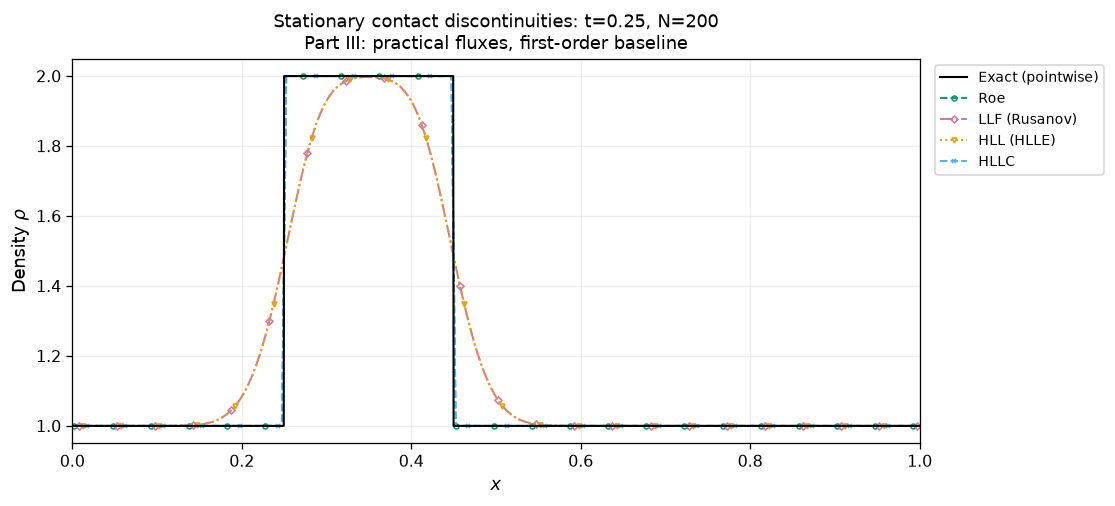

method,n,order,status,t_reached,L1_rho,rho_min,p_min,balance_max
Roe,200,1,ok,0.25,0,1,1,0
LLF (Rusanov),200,1,ok,0.25,0.05605,1,1,8.882e-16
HLL (HLLE),200,1,ok,0.25,0.05583,1,1,6.661e-16
HLLC,200,1,ok,0.25,0,1,1,0


[{'problem': 'contact_static',
  'solver': 'Roe',
  'order': 1,
  'n': 200,
  'cfl': 0.4,
  'limiter': 'constant',
  'wave_speeds': 'einfeldt',
  'roe_entropy': 0.1,
  'status': 'ok',
  't_reached': 0.25,
  't_target': 0.25,
  'steps': 148,
  'seconds': 0.02877083600000674,
  'rho_min': 1.0,
  'p_min': 1.0,
  'balance_max': 0.0,
  'mass_balance': np.float64(0.0),
  'momentum_balance': np.float64(0.0),
  'energy_balance': np.float64(0.0),
  'L1_rho': np.float64(0.0),
  'L1_u': np.float64(0.0),
  'L1_p': np.float64(0.0),
  'amp_ratio': nan,
  'phase_rad': nan,
  'rho_overshoot': 0.0,
  'rho_undershoot': 0.0,
  'mixed_length': 0.0,
  'failure_trial_end': nan,
  'failure_dt': nan,
  'failure_rho_min': nan,
  'failure_p_min': nan,
  'failure_reason': '',
  'method': 'Roe'},
 {'problem': 'contact_static',
  'solver': 'LLF',
  'order': 1,
  'n': 200,
  'cfl': 0.4,
  'limiter': 'constant',
  'wave_speeds': 'einfeldt',
  'roe_entropy': 0.1,
  'status': 'ok',
  't_reached': 0.25,
  't_target': 0

In [5]:
RESULTS[("modern", "contact_static")] = run_part("modern", "contact_static", CFG)
runs = RESULTS[("modern", "contact_static")]
plot_profiles(runs, fields=('rho',), logarithmic=False, title_suffix=PARTS["modern"]["title"])
summarize(runs)

### III.3 移動する接触面

接触波を区別するRoe/HLLCでも、1次精度の移流では不連続面が広がります。静止接触面との違いを説明してください。

Part III: practical fluxes, first-order baseline | contact: Roe=ok, LLF (Rusanov)=ok, HLL (HLLE)=ok, HLLC=ok


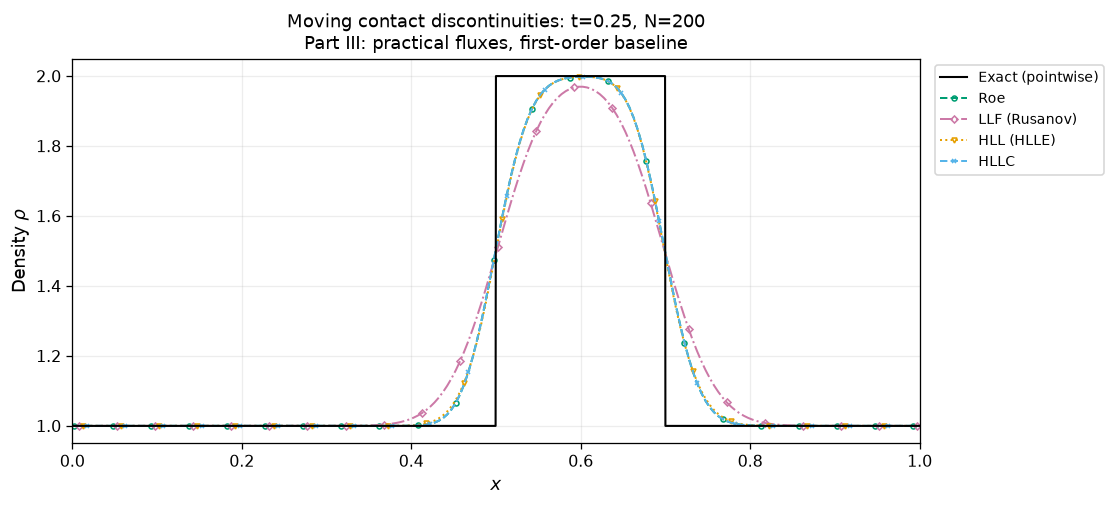

method,n,order,status,t_reached,L1_rho,rho_min,p_min,balance_max
Roe,200,1,ok,0.25,0.0509,1,1,4.441e-16
LLF (Rusanov),200,1,ok,0.25,0.07569,1,1,8.882e-16
HLL (HLLE),200,1,ok,0.25,0.05164,1,1,4.441e-16
HLLC,200,1,ok,0.25,0.0509,1,1,6.661e-16


[{'problem': 'contact',
  'solver': 'Roe',
  'order': 1,
  'n': 200,
  'cfl': 0.4,
  'limiter': 'constant',
  'wave_speeds': 'einfeldt',
  'roe_entropy': 0.1,
  'status': 'ok',
  't_reached': 0.25,
  't_target': 0.25,
  'steps': 273,
  'seconds': 0.05393347700000106,
  'rho_min': 0.9999999999999996,
  'p_min': 0.9999999999999987,
  'balance_max': 4.440892098500626e-16,
  'mass_balance': np.float64(4.440892098500626e-16),
  'momentum_balance': np.float64(4.440892098500626e-16),
  'energy_balance': np.float64(-4.440892098500626e-16),
  'L1_rho': np.float64(0.05090281253769147),
  'L1_u': np.float64(2.581268532253489e-16),
  'L1_p': np.float64(3.552713678800501e-16),
  'amp_ratio': nan,
  'phase_rad': nan,
  'rho_overshoot': 0.0,
  'rho_undershoot': 4.440892098500626e-16,
  'mixed_length': 0.16,
  'failure_trial_end': nan,
  'failure_dt': nan,
  'failure_rho_min': nan,
  'failure_p_min': nan,
  'failure_reason': '',
  'method': 'Roe'},
 {'problem': 'contact',
  'solver': 'LLF',
  'order':

In [6]:
RESULTS[("modern", "contact")] = run_part("modern", "contact", CFG)
runs = RESULTS[("modern", "contact")]
plot_profiles(runs, fields=('rho',), logarithmic=False, title_suffix=PARTS["modern"]["title"])
summarize(runs)

### III.4 Sod衝撃波管

接触面と衝撃波を密度・圧力・速度から見分けます。どちらの構造で流束間の差が大きいか確認します。

Part III: practical fluxes, first-order baseline | sod: Roe=ok, LLF (Rusanov)=ok, HLL (HLLE)=ok, HLLC=ok


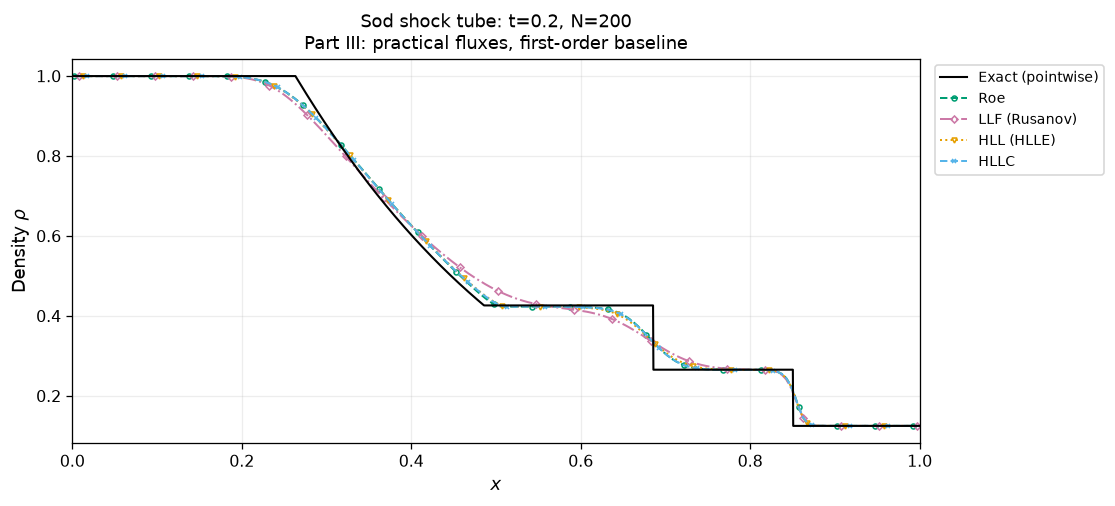

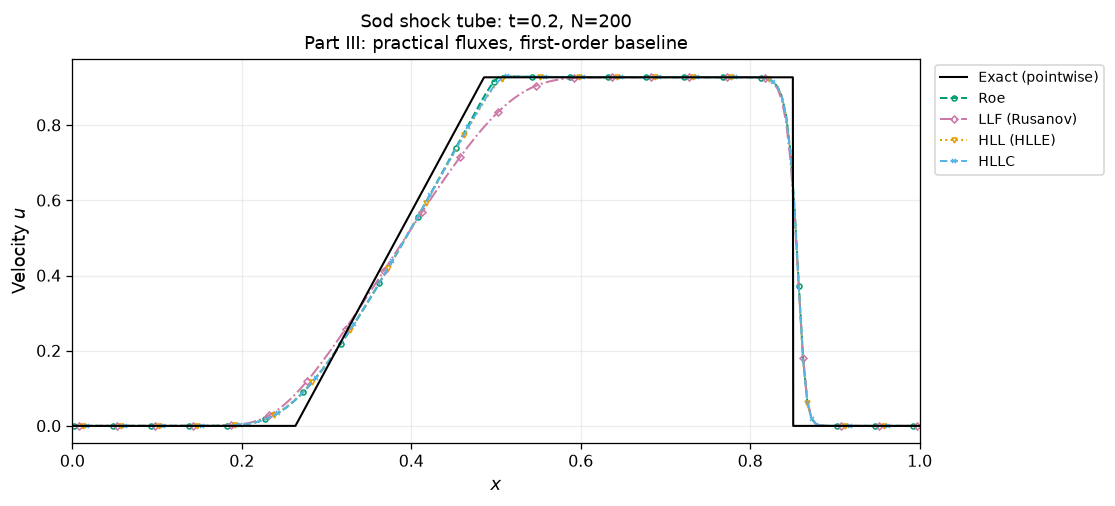

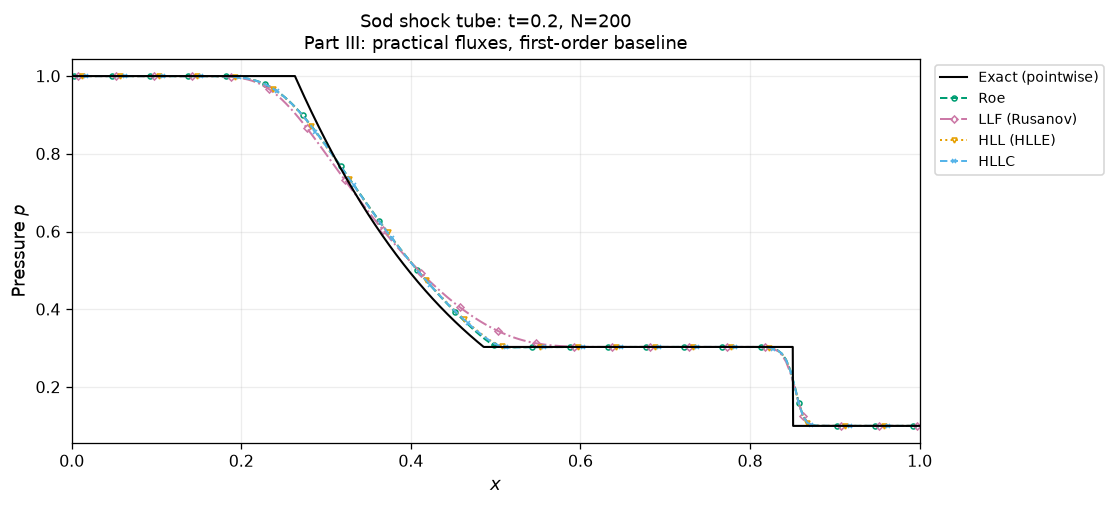

method,n,order,status,t_reached,L1_rho,rho_min,p_min,balance_max
Roe,200,1,ok,0.2,0.01122,0.125,0.1,5.546e-16
LLF (Rusanov),200,1,ok,0.2,0.01681,0.125,0.1,1.334e-15
HLL (HLLE),200,1,ok,0.2,0.01213,0.125,0.1,3.339e-16
HLLC,200,1,ok,0.2,0.01149,0.125,0.1,6.643e-16


[{'problem': 'sod',
  'solver': 'Roe',
  'order': 1,
  'n': 200,
  'cfl': 0.4,
  'limiter': 'constant',
  'wave_speeds': 'einfeldt',
  'roe_entropy': 0.1,
  'status': 'ok',
  't_reached': 0.2,
  't_target': 0.2,
  'steps': 216,
  'seconds': 0.04317439499999409,
  'rho_min': 0.125,
  'p_min': 0.1,
  'balance_max': 5.545540091383796e-16,
  'mass_balance': np.float64(5.545540091383796e-16),
  'momentum_balance': np.float64(-5.551115123125783e-17),
  'energy_balance': np.float64(-4.460404709597581e-16),
  'L1_rho': np.float64(0.011221602348175408),
  'L1_u': np.float64(0.017554303236962686),
  'L1_p': np.float64(0.009358074883863232),
  'amp_ratio': nan,
  'phase_rad': nan,
  'rho_overshoot': nan,
  'rho_undershoot': nan,
  'mixed_length': nan,
  'failure_trial_end': nan,
  'failure_dt': nan,
  'failure_rho_min': nan,
  'failure_p_min': nan,
  'failure_reason': '',
  'method': 'Roe'},
 {'problem': 'sod',
  'solver': 'LLF',
  'order': 1,
  'n': 200,
  'cfl': 0.4,
  'limiter': 'constant',
  

In [7]:
RESULTS[("modern", "sod")] = run_part("modern", "sod", CFG)
runs = RESULTS[("modern", "sod")]
plot_profiles(runs, fields=('rho', 'u', 'p'), logarithmic=False, title_suffix=PARTS["modern"]["title"])
summarize(runs)

### III.5 二重希薄波

エントロピー補正と正値性の検査は別です。完走の有無と、完走した解の精度を分けて評価します。

Part III: practical fluxes, first-order baseline | double_rarefaction: Roe=failed, LLF (Rusanov)=ok, HLL (HLLE)=ok, HLLC=ok


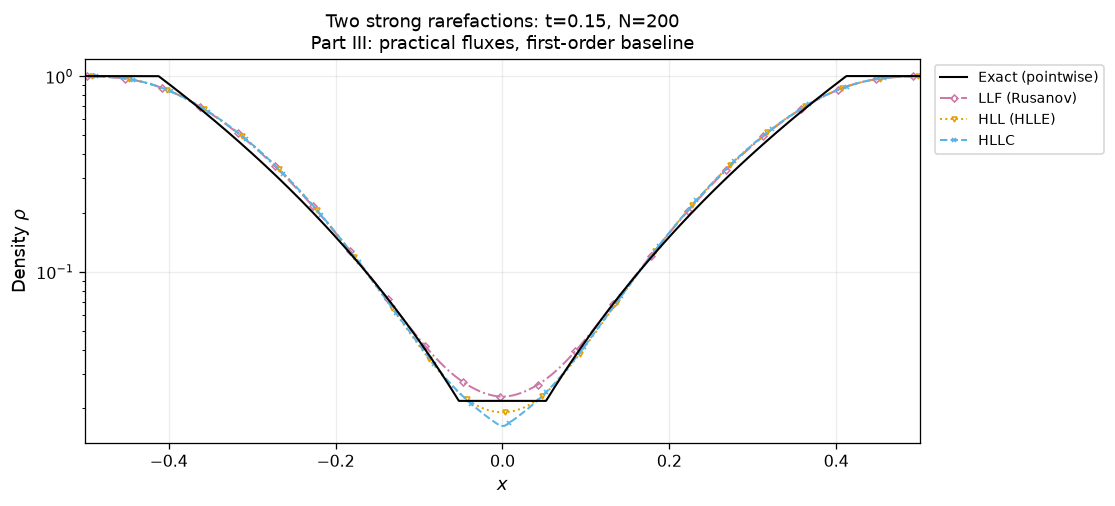

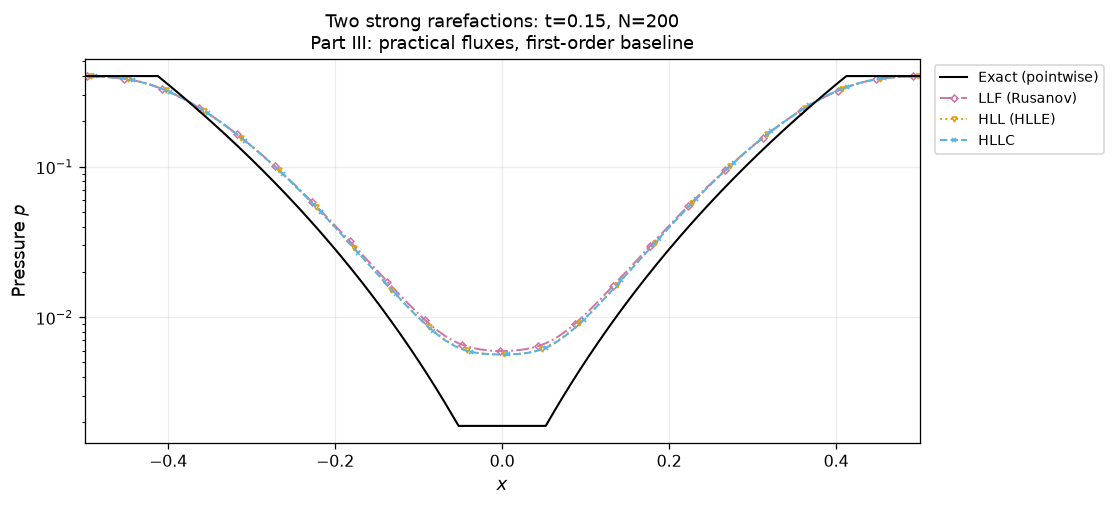

Roe: stopped at last accepted t=0.00072771426; rejected trial ended at t=0.0014554285.
  full-step update:  min(rho)=4.67235e-01, min(p)=-3.14328e-01


method,n,order,status,t_reached,L1_rho,rho_min,p_min,balance_max
Roe,200,1,failed,0.0007277,—,0.7089,0.0262,4.901e-17
LLF (Rusanov),200,1,ok,0.15,0.02086,0.023,0.005954,2.665e-15
HLL (HLLE),200,1,ok,0.15,0.02173,0.01913,0.005653,2.22e-15
HLLC,200,1,ok,0.15,0.02183,0.01628,0.005648,2.22e-15


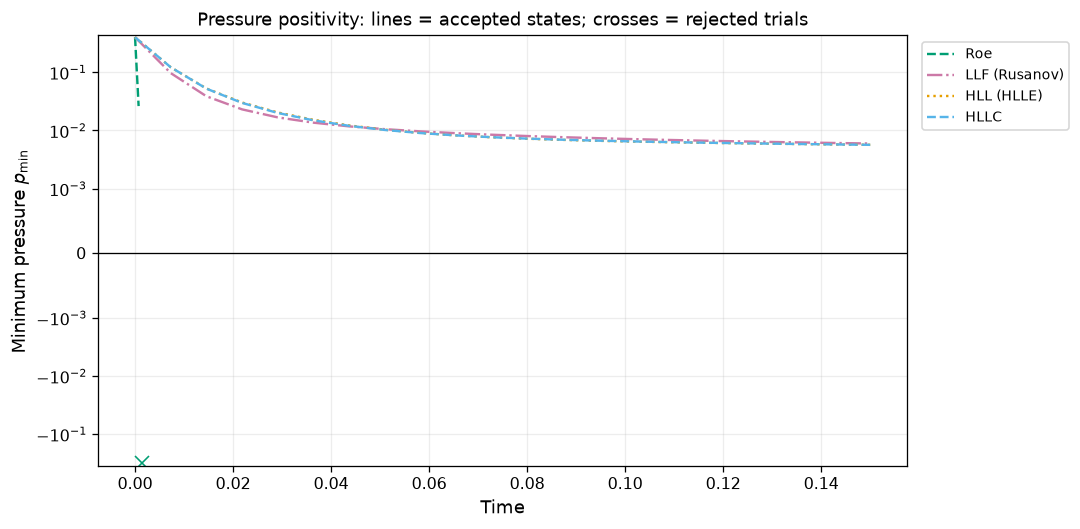

In [8]:
RESULTS[("modern", "double_rarefaction")] = run_part("modern", "double_rarefaction", CFG)
runs = RESULTS[("modern", "double_rarefaction")]
plot_profiles(runs, fields=('rho', 'p'), logarithmic=True, title_suffix=PARTS["modern"]["title"])
summarize(runs)
plot_pressure_minimum(runs)

### III.6 1次精度の基準

4流束に共通の低次精度構成で収束次数を測り、第IV部との比較の基準にします。

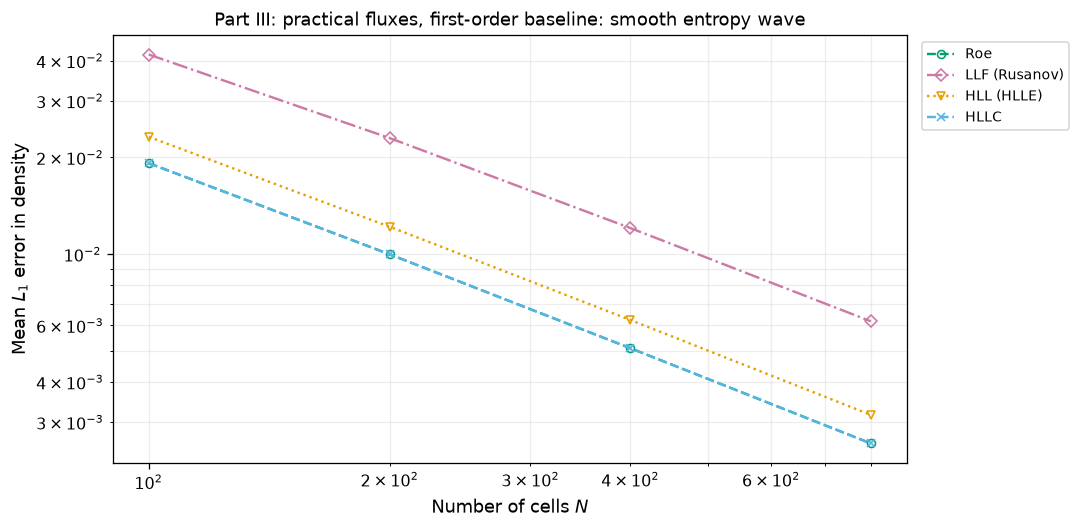

method,order,n,L1_rho,q_observed
Roe,1,100,0.01918,—
Roe,1,200,0.009984,0.9416
Roe,1,400,0.005095,0.9705
Roe,1,800,0.002574,0.9851
LLF (Rusanov),1,100,0.04177,—
LLF (Rusanov),1,200,0.02296,0.8631
LLF (Rusanov),1,400,0.01205,0.9301
LLF (Rusanov),1,800,0.006175,0.9647
HLL (HLLE),1,100,0.02315,—
HLL (HLLE),1,200,0.01216,0.9283


In [9]:
if CFG["run_convergence"]:
    convergence_II = run_convergence("modern", CFG)

### 第III部のまとめ
数値流束の差を調べるため、空間再構築と時間積分を固定します。
「Roe」「HLLC」という名前だけで計算全体が決まるわけではないことを、次の部で確認します。

## 時間発展の動画

動画は標準で表示します。`CFG["run_movies"] = False` にすると省略できます。`movie_problem` の問題を本冊の手法だけで比較します。初期値はSodです。
`FrameRecorder` を使い、フレーム出力のために数値積分の時間刻みを変更しません。
記録の有無で最終状態・ステップ数・境界流束が一致することを検査します。
**失敗した方式は停止時刻以降に描画しません。** 表示はJavaScriptアニメーションで、ffmpegは不要です。
この簡易動画はShu–Osherには対応しません。

In [10]:
if CFG["run_movies"]:
    fig, movie = make_part_animation(PART, CFG["movie_problem"], CFG, n_frames=CFG["movie_frames"])
    display(HTML(movie.to_jshtml()))
    plt.close(fig)

## 任意：Shu–Osher問題

`CFG["run_shu_osher"] = True` で有効です。定義した初期条件と2解像度の数値参照解を用います。
黒線は**数値参照解であり厳密解ではありません**。粗い参照解と細かい参照解の差も表示します。
参照解を含め、必要な計算は本冊だけで実行します。図の比較対象は本冊の手法に限定します。
高解像度参照解は計算量が多いため、基本演習の後に実行してください。

In [11]:
if CFG["run_shu_osher"]:
    reference_fine = shu_reference(CFG)
    runs = run_part(PART, "shu_osher", CFG, n=CFG["n_shu_osher"])
    RESULTS[(PART, "shu_osher")] = runs
    plot_profiles(runs, reference=reference_fine, xlim=(-1.0, 2.3), title_suffix=PARTS[PART]["title"])
    summarize(runs, reference=reference_fine)

## 任意：追加実験

`CFG["run_extras"] = True` で有効です。
Lax衝撃波管を本冊の手法で比較します。
LFとLLF (Rusanov)のCFL数依存性、Roeのエントロピー補正の有無も比較します。
この補助比較に限り古典的LFを含めますが、必要なLFの計算も本冊の中で実行します。
Laxは**問題名**で、使うスキームをLF/LWに限定する意味ではありません。

In [12]:
if CFG["run_extras"]:
    runs = run_part(PART, "lax", CFG)
    RESULTS[(PART, "lax")] = runs
    plot_profiles(runs, title_suffix=PARTS[PART]["title"])
    summarize(runs)
    cfl_runs = [get_run("entropy", s, CFG, cfl=c) for s in ("LF", "LLF") for c in (0.2, 0.4, 0.8)]
    summarize(cfl_runs, columns=("method", "cfl", "n", "L1_rho", "amp_ratio", "phase_rad"))
    roe_runs = [get_run("transonic", "Roe", CFG, roe_entropy=e) for e in (0.0, 0.1)]
    summarize(roe_runs, columns=("method", "roe_entropy", "status", "L1_rho", "p_min"))

## 結果の保存

本冊の計算結果を `four_part_outputs/` の **本冊専用サブフォルダー**に保存し、他の冊の結果を上書きしません。
同じ冊を同じ設定で実行し直すと、その冊の保存ファイルを更新します。
CSVに内部識別子 `solver`、表示名 `method`、学習分類 `part` を分けて記録します。
NPZの状態配列の番号はCSVの行順に対応します。停止した計算の誤差は最終時刻の誤差として扱いません。
参照解や部をまたぐ補助比較を有効にした場合は、それらの計算も本冊の出力に含みます。

In [13]:
if CFG["export_results"]:
    saved_rows = export_results(OUTPUT_DIR, CFG, reference=reference_fine)
    failed_rows = [r for r in saved_rows if r["status"] != "ok"]
    print("Distinct runs:", len(saved_rows), "Recorded failures/incomplete runs:", len(failed_rows))
    show_table(failed_rows, ("part", "problem", "method", "order", "t_reached", "failure_trial_end", "failure_p_min"))

Saved 32 distinct runs to /home/runner/work/euler1d-scheme-comparison/euler1d-scheme-comparison/four_part_outputs/modern
Distinct runs: 32 Recorded failures/incomplete runs: 1


part,problem,method,order,t_reached,failure_trial_end,failure_p_min
modern,double_rarefaction,Roe,1,0.0007277,0.001455,-0.3143


## 次の学習

[第IV部](04_spatial_reconstruction.ipynb)では空間再構築を、[第V部](05_time_integration.ipynb)では時間積分を比較します。
第IV部は区分一定・MUSCLとリミッター、第V部は前進Euler・SSP-RK2・SSP-RK3を扱います。PPM・WENOは対象外です。

## 参考文献・実装の確認先

以下は原論文または開発者による公式資料です。Notebookのコードはこれらの数式・考え方を参考に、本教材用に組み立てた実装であり、Clawpack等を呼び出してはいません。

**[R1]** Clawpack, *The Euler equations of gas dynamics*：波の構造と厳密リーマン解。  
https://www.clawpack.org/riemann_book/html/Euler.html

**[R2]** Clawpack, *Approximate solvers for the Euler equations of gas dynamics*：Roe平均、HLLEの波速推定、低密度問題。  
https://www.clawpack.org/riemann_book/html/Euler_approximate.html

**[R3]** Clawpack, *Riemann Solver Package — Euler Equations*：HLLCの接触波速度と中間状態。  
https://www.clawpack.org/pyclaw/rp.html#euler-equations

**[R4]** FLASH User's Guide, *Hydrodynamics Test Problems*, §35.1.1：Sod問題と波面の位置。  
https://flash.rochester.edu/site/flashcode/user_support/flash_ug_devel/node191.html

**[R5]** Clawpack Gallery, *Shu–Osher problem*：初期状態、領域、終了時刻。  
https://www.clawpack.org/gallery/pyclaw/gallery/shocksine.html

**[R6]** Toro, E. F., Spruce, M., & Speares, W. (1994), *Restoration of the contact surface in the HLL-Riemann solver*, Shock Waves, 4, 25–34.  
https://doi.org/10.1007/BF01414629

**[R7]** Harten, A. (1983), *High resolution schemes for hyperbolic conservation laws*, Journal of Computational Physics, 49, 357–393.  
https://doi.org/10.1016/0021-9991(83)90136-5

**[R8]** Shu, C.-W., & Osher, S. (1988), *Efficient implementation of essentially non-oscillatory shock-capturing schemes*, Journal of Computational Physics, 77, 439–471.  
https://doi.org/10.1016/0021-9991(88)90177-5

**[R9]** Shu, C.-W., & Osher, S. (1989), *Efficient implementation of essentially non-oscillatory shock-capturing schemes, II*, Journal of Computational Physics, 83, 32–78.  
https://doi.org/10.1016/0021-9991(89)90222-2

初期条件・波速推定・エントロピー補正・リミッター・CFL数まで含めて、比較の設定を報告することが重要です。
「Roe」や「HLLC」という名前だけでは、実装のすべては決まりません。